## 1. Load the model and upload photos

# Saliency map randomization experiment


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 2017-09-12_Atlantic_Airways_(Faroe_Islands)_Airbus_A319_aircraft_(OY-RCG)_at_Narsarsuaq,_Greenland.jpg to 2017-09-12_Atlantic_Airways_(Faroe_Islands)_Airbus_A319_aircraft_(OY-RCG)_at_Narsarsuaq,_Greenland (1).jpg
Saving A_bottle_of_cold_water_with_droplets.jpg to A_bottle_of_cold_water_with_droplets.jpg
Saving Aeroflot_Airbus_A330_Kustov.jpg to Aeroflot_Airbus_A330_Kustov (1).jpg
Saving Air-to-air_photo_of_a_Sukhoi_Superjet_100_(97004)_over_Italy.jpg to Air-to-air_photo_of_a_Sukhoi_Superjet_100_(97004)_over_Italy (1).jpg
Saving Audi_e-tron_(Edit1).jpg to Audi_e-tron_(Edit1).jpg
Saving Banana_dágua.jpg to Banana_dágua.jpg
Saving Banana_on_whitebackground.jpg to Banana_on_whitebackground.jpg
Saving Banana_sugar_spot.jpg to Banana_sugar_spot.jpg
Saving Bananas_on_black_background_02.jpg to Bananas_on_black_background_02.jpg
Saving Banana-Sitia-Crete.jpg to Banana-Sitia-Crete.jpg
Saving Bottle_of_water.jpg to Bottle_of_water.jpg
Saving Cat_Sphynx._Kittens._img_11.jpg to Cat_Sphynx._

In [ ]:
# @title Default title text
from copy import deepcopy
from io import BytesIO

import matplotlib.pyplot as plt
import pandas as pd
import torch
from google.colab import files
from PIL import Image, ImageOps
from scipy.stats import spearmanr
from torchvision.models import ResNet18_Weights, resnet18

SEEDS = [42, 44, 46]

weights = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=weights).eval()
preprocess = weights.transforms()

uploaded = files.upload()
if not uploaded:
    raise ValueError("Upload at least one JPG or PNG image.")

print(f"Loaded {len(uploaded)} image(s).")

Saving 2017-09-12_Atlantic_Airways_(Faroe_Islands)_Airbus_A319_aircraft_(OY-RCG)_at_Narsarsuaq,_Greenland.jpg to 2017-09-12_Atlantic_Airways_(Faroe_Islands)_Airbus_A319_aircraft_(OY-RCG)_at_Narsarsuaq,_Greenland (2).jpg
Saving A_bottle_of_cold_water_with_droplets.jpg to A_bottle_of_cold_water_with_droplets (1).jpg
Saving Aeroflot_Airbus_A330_Kustov.jpg to Aeroflot_Airbus_A330_Kustov (2).jpg
Saving Air-to-air_photo_of_a_Sukhoi_Superjet_100_(97004)_over_Italy.jpg to Air-to-air_photo_of_a_Sukhoi_Superjet_100_(97004)_over_Italy (2).jpg
Saving Audi_e-tron_(Edit1).jpg to Audi_e-tron_(Edit1) (1).jpg
Saving Banana_dágua.jpg to Banana_dágua (1).jpg
Saving Banana_on_whitebackground.jpg to Banana_on_whitebackground (1).jpg
Saving Banana_sugar_spot.jpg to Banana_sugar_spot (1).jpg
Saving Bananas_on_black_background_02.jpg to Bananas_on_black_background_02 (1).jpg
Saving Banana-Sitia-Crete.jpg to Banana-Sitia-Crete (1).jpg
Saving Bottle_of_water.jpg to Bottle_of_water (1).jpg
Saving Cat_Sphynx._Kit

## 2. Run the experiment

Each photo keeps the class predicted by the pretrained model throughout the cascade. Every reset stage is compared with the original maps for that photo.

In [ ]:
def make_gradcam(model_to_test, input_batch, target_class):
    captured = []

    def save_maps(module, inputs, output):
        captured.append(output)

    hook = model_to_test.layer4[-1].register_forward_hook(save_maps)
    scores = model_to_test(input_batch)
    hook.remove()

    maps = captured[0]
    score = scores[0, target_class]
    gradients = torch.autograd.grad(score, maps)[0]
    weights = gradients.mean(dim=(2, 3), keepdim=True)

    return (maps.detach() * weights).sum(dim=1).relu()[0]


def keep_positive_gradients(module, grad_input, grad_output):
    return (grad_input[0].clamp(min=0),)


def make_guided_gradients(model_to_test, input_batch, target_class):
    guided_copy = deepcopy(model_to_test)
    image_for_gradients = input_batch.detach().clone().requires_grad_(True)

    hooks = []
    for layer in guided_copy.modules():
        if isinstance(layer, torch.nn.ReLU):
            layer.inplace = False
            hooks.append(
                layer.register_full_backward_hook(keep_positive_gradients)
            )

    score = guided_copy(image_for_gradients)[0, target_class]
    gradients = torch.autograd.grad(score, image_for_gradients)[0]

    for hook in hooks:
        hook.remove()

    return gradients


def rank_similarity(before, after):
    before_values = before.detach().cpu().flatten().numpy()
    after_values = after.detach().cpu().flatten().numpy()
    if before_values.min() == before_values.max() or after_values.min() == after_values.max():
        return float("nan")
    return spearmanr(before_values, after_values)[0]

In [ ]:
stages = [
    ("fc", ()),
    ("fc + layer4", ("layer4",)),
    ("+ layer3", ("layer3",)),
    ("+ layer2", ("layer2",)),
    ("+ layer1", ("layer1",)),
    ("+ stem", ("conv1", "bn1")),
]

rows = []
example = {}

for image_name, image_bytes in uploaded.items():
    with Image.open(BytesIO(image_bytes)) as image:
        input_batch = preprocess(ImageOps.exif_transpose(image).convert("RGB")).unsqueeze(0)

    with torch.no_grad():
        target_class = model(input_batch)[0].argmax().item()

    class_name = weights.meta["categories"][target_class]
    print(f"{image_name} → {class_name} ({target_class})")

    original_cam = make_gradcam(model, input_batch, target_class)
    original_guided = make_guided_gradients(model, input_batch, target_class)
    original_magnitude = original_guided.abs()

    for seed in SEEDS:
        # Preserve the initialization used in the original seed-42 pilot.
        torch.manual_seed(seed)
        test_model = deepcopy(model)
        test_model.fc.reset_parameters()

        torch.manual_seed(seed + 1)
        fresh_model = resnet18(weights=None)

        for stage, layer_names in stages:
            for name in layer_names:
                getattr(test_model, name).load_state_dict(
                    getattr(fresh_model, name).state_dict()
                )

            cam = make_gradcam(test_model, input_batch, target_class)
            guided = make_guided_gradients(test_model, input_batch, target_class)
            magnitude = guided.abs()

            rows.append({
                "image": image_name,
                "target_class": target_class,
                "class_name": class_name,
                "seed": seed,
                "stage": stage,
                "gradcam": rank_similarity(original_cam, cam),
                "guided_abs_rgb": rank_similarity(original_magnitude, magnitude),
                "guided_signed_rgb": rank_similarity(original_guided, guided),
            })

            if not example:
                example = {
                    "image": image_name,
                    "class_name": class_name,
                    "before_cam": original_cam,
                    "after_cam": cam,
                    "before_guided": original_magnitude[0].amax(dim=0),
                    "after_guided": magnitude[0].amax(dim=0),
                }

2017-09-12_Atlantic_Airways_(Faroe_Islands)_Airbus_A319_aircraft_(OY-RCG)_at_Narsarsuaq,_Greenland (2).jpg → airliner (404)
A_bottle_of_cold_water_with_droplets (1).jpg → water bottle (898)
Aeroflot_Airbus_A330_Kustov (2).jpg → airliner (404)
Air-to-air_photo_of_a_Sukhoi_Superjet_100_(97004)_over_Italy (2).jpg → airliner (404)
Audi_e-tron_(Edit1) (1).jpg → sports car (817)
Banana_dágua (1).jpg → banana (954)
Banana_on_whitebackground (1).jpg → banana (954)
Banana_sugar_spot (1).jpg → banana (954)
Bananas_on_black_background_02 (1).jpg → banana (954)
Banana-Sitia-Crete (1).jpg → banana (954)
Bottle_of_water (1).jpg → water bottle (898)
Cat_Sphynx._Kittens._img_11 (1).jpg → Mexican hairless (268)
Charadrius-melodus-004 (1).jpg → ruddy turnstone (139)
Curious_cat_starring_at_a_lizard (1).jpg → Egyptian cat (285)
Die_Wildkatze_in_der_Wildnis (1).jpg → lynx (287)
Dog,_Baku_(P1090239) (1).jpg → dingo (273)
Dog_in_a_muzzle (1).jpg → muzzle (676)
Domestic_cat_2019_G1 (1).jpg → tabby (281)
DTM_

## 3. Save and inspect results

The CSV has one row per image, seed, and reset stage. Use the Colab Files panel to download `saliency_results.csv` after the run. Correlations for constant maps are undefined and appear as blank CSV values.

Saved 720 rows to main_results.csv.


,image,target_class,class_name,seed,stage,gradcam,guided_abs_rgb,guided_signed_rgb
0,2017-09-12_Atlantic_Airways_(Faroe_Islands)_Ai...,404,airliner,42,fc,0.478738,0.984317,0.995640
1,2017-09-12_Atlantic_Airways_(Faroe_Islands)_Ai...,404,airliner,42,fc + layer4,-0.643537,0.836311,0.951973
2,2017-09-12_Atlantic_Airways_(Faroe_Islands)_Ai...,404,airliner,42,+ layer3,-0.364482,0.808544,0.895491
3,2017-09-12_Atlantic_Airways_(Faroe_Islands)_Ai...,404,airliner,42,+ layer2,-0.102472,0.591346,0.745717
4,2017-09-12_Atlantic_Airways_(Faroe_Islands)_Ai...,404,airliner,42,+ layer1,-0.477161,0.327386,0.572009
...,...,...,...,...,...,...,...,...
715,Watsons_Water_minerals_800mL (1).JPG,898,water bottle,46,fc + layer4,-0.327683,0.914343,0.967865
716,Watsons_Water_minerals_800mL (1).JPG,898,water bottle,46,+ layer3,0.274576,0.770159,0.854165
717,Watsons_Water_minerals_800mL (1).JPG,898,water bottle,46,+ layer2,0.245918,0.465786,0.591856
718,Watsons_Water_minerals_800mL (1).JPG,898,water bottle,46,+ layer1,0.564147,0.248092,0.431494


Valid correlations per stage:


,gradcam,guided_abs_rgb,guided_signed_rgb
stage,,,
fc,116,120,120
fc + layer4,115,120,120
+ layer3,112,120,120
+ layer2,107,120,120
+ layer1,104,120,120
+ stem,109,120,120


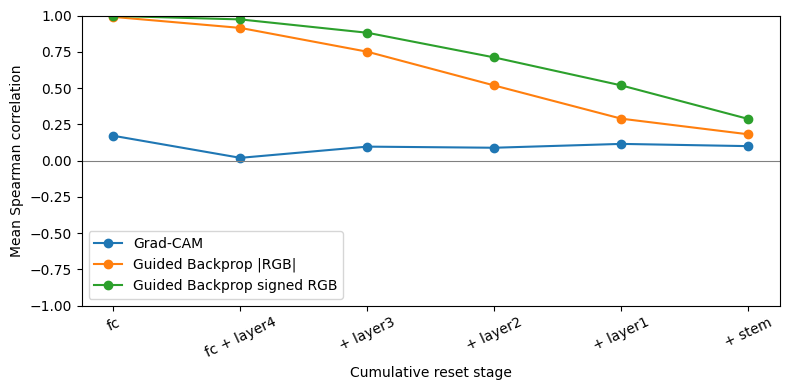

In [ ]:
results = pd.DataFrame(rows)
results.to_csv("main_results.csv", index=False)
print(f"Saved {len(results)} rows to main_results.csv.")
display(results)

metrics = ["gradcam", "guided_abs_rgb", "guided_signed_rgb"]
stage_order = [stage for stage, _ in stages]
labels = ["Grad-CAM", "Guided Backprop |RGB|", "Guided Backprop signed RGB"]
summary = results.groupby("stage")[metrics].mean().reindex(stage_order)
counts = results.groupby("stage")[metrics].count().reindex(stage_order)

if results[metrics].isna().any().any():
    print("Valid correlations per stage:")
    display(counts)

ax = summary.set_axis(labels, axis=1).plot(marker="o", figsize=(8, 4), rot=25)
ax.set_xlabel("Cumulative reset stage")
ax.set_ylabel("Mean Spearman correlation")
ax.set_ylim(-1, 1)
ax.axhline(0, color="gray", linewidth=0.8)
plt.tight_layout()
plt.show()

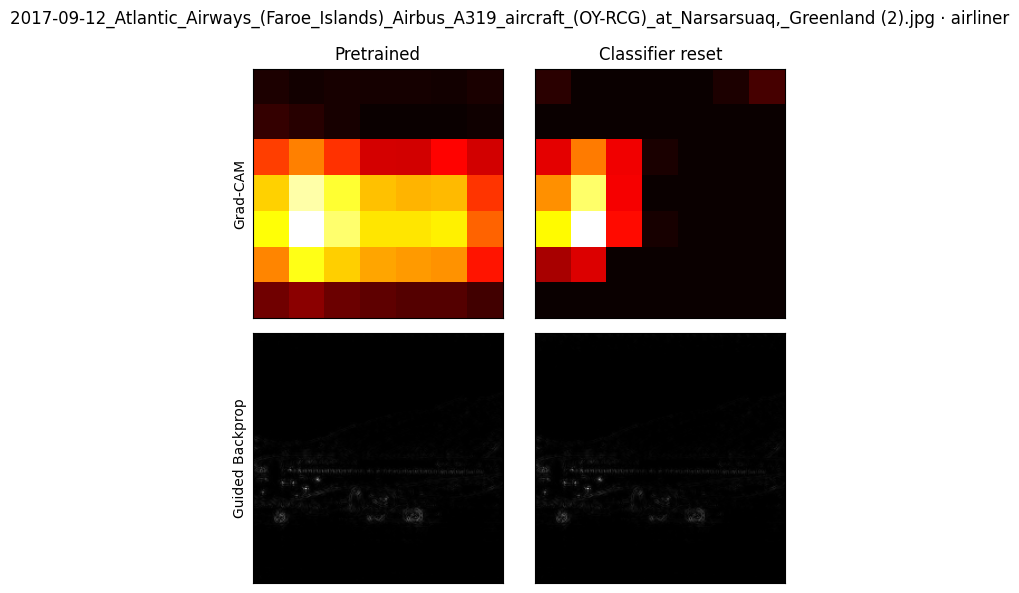

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(6, 6))
fig.suptitle(f"{example['image']} · {example['class_name']}")

axes[0, 0].set_title("Pretrained")
axes[0, 1].set_title("Classifier reset")
axes[0, 0].imshow(example["before_cam"], cmap="hot", interpolation="nearest", vmin=0)
axes[0, 1].imshow(example["after_cam"], cmap="hot", interpolation="nearest", vmin=0)
axes[1, 0].imshow(example["before_guided"], cmap="gray", vmin=0)
axes[1, 1].imshow(example["after_guided"], cmap="gray", vmin=0)

for row_index, label in enumerate(["Grad-CAM", "Guided Backprop"]):
    axes[row_index, 0].set_ylabel(label)
    for axis in axes[row_index]:
        axis.set_xticks([])
        axis.set_yticks([])

plt.tight_layout()
plt.show()

## 4. Validate main results and summarize spread

Verify that every image in `main_results.csv` has all 3 seeds and all 6 cumulative reset stages with no duplicate rows. Count undefined (`NaN`) Grad-CAM correlations per stage, average across seeds for each image, summarize the median and interquartile range (IQR) across images, and check how consistently Grad-CAM shows lower similarity than Guided Backpropagation at the `fc`-only reset.

In [ ]:
df = pd.read_csv("main_results.csv")
metrics = ["gradcam", "guided_abs_rgb", "guided_signed_rgb"]
stage_order = [stage for stage, _ in stages]

# 1. Check completeness (3 seeds x 6 stages = 18 rows/image) and no duplicates
expected_rows = len(SEEDS) * len(stages)
rows_per_image = df.groupby("image").size()
dup_count = df.duplicated(subset=["image", "seed", "stage"]).sum()

print(f"Images: {df['image'].nunique()} | Total rows: {len(df)} | Duplicate rows: {dup_count}")
assert (rows_per_image == expected_rows).all(), "Missing seed/stage rows detected!"
assert dup_count == 0, "Duplicate rows detected!"
print("Check passed: all images have 3 seeds and 6 stages with 0 duplicates.\n")

# 2. Count undefined (blank/NaN) Grad-CAM correlations per stage
stage_counts = pd.DataFrame({
    "valid_gradcam_rows": df.groupby("stage")["gradcam"].count().reindex(stage_order),
    "undefined_gradcam_rows": df.groupby("stage")["gradcam"].apply(lambda s: s.isna().sum()).reindex(stage_order),
})
print("Grad-CAM valid vs. undefined counts across all image-seed runs:")
display(stage_counts)

# 3. Average across seeds for each image, then summarize spread (median & IQR) across images
per_image = df.groupby(["image", "target_class", "class_name", "stage"], as_index=False)[metrics].mean()

summary_table = []
for st in stage_order:
    sub = per_image[per_image["stage"] == st]
    row = {
        "stage": st,
        "valid_images_gradcam": int(sub["gradcam"].notna().sum()),
    }
    for m in metrics:
        q25, med, q75 = sub[m].quantile([0.25, 0.50, 0.75])
        row[f"{m}_median"] = round(med, 3)
        row[f"{m}_IQR"] = f"[{q25:.3f}, {q75:.3f}]"
    summary_table.append(row)

print("\nSeed-averaged median and middle-50% spread (IQR) across images:")
display(pd.DataFrame(summary_table))

# 4. Classifier-only ('fc') reset consistency count
fc_df = per_image[per_image["stage"] == "fc"].dropna(subset=["gradcam"])
n_fc = len(fc_df)
n_lower_abs = int((fc_df["gradcam"] < fc_df["guided_abs_rgb"]).sum())
n_lower_signed = int((fc_df["gradcam"] < fc_df["guided_signed_rgb"]).sum())

print(f"\nClassifier-only ('fc') reset consistency (out of {n_fc} valid images):")
print(f"  Grad-CAM < Guided Backprop |RGB|:      {n_lower_abs}/{n_fc} ({100 * n_lower_abs / n_fc:.1f}%)")
print(f"  Grad-CAM < Guided Backprop signed RGB: {n_lower_signed}/{n_fc} ({100 * n_lower_signed / n_fc:.1f}%)")

Images: 40 | Total rows: 720 | Duplicate rows: 0
Check passed: all images have 3 seeds and 6 stages with 0 duplicates.

Grad-CAM valid vs. undefined counts across all image-seed runs:


,valid_gradcam_rows,undefined_gradcam_rows
stage,,
fc,116,4
fc + layer4,115,5
+ layer3,112,8
+ layer2,107,13
+ layer1,104,16
+ stem,109,11



Seed-averaged median and middle-50% spread (IQR) across images:


,stage,valid_images_gradcam,gradcam_median,gradcam_IQR,guided_abs_rgb_median,guided_abs_rgb_IQR,guided_signed_rgb_median,guided_signed_rgb_IQR
0,fc,40,0.166,"[-0.052, 0.390]",0.991,"[0.988, 0.994]",0.997,"[0.996, 0.998]"
1,fc + layer4,40,0.023,"[-0.082, 0.129]",0.926,"[0.888, 0.952]",0.977,"[0.965, 0.985]"
2,+ layer3,40,0.075,"[-0.009, 0.178]",0.749,"[0.701, 0.799]",0.885,"[0.865, 0.906]"
3,+ layer2,40,0.091,"[-0.050, 0.180]",0.527,"[0.474, 0.575]",0.729,"[0.680, 0.762]"
4,+ layer1,39,0.155,"[0.033, 0.239]",0.297,"[0.244, 0.340]",0.532,"[0.479, 0.567]"
5,+ stem,40,0.091,"[-0.019, 0.207]",0.173,"[0.137, 0.210]",0.295,"[0.272, 0.312]"



Classifier-only ('fc') reset consistency (out of 40 valid images):
  Grad-CAM < Guided Backprop |RGB|:      40/40 (100.0%)
  Grad-CAM < Guided Backprop signed RGB: 40/40 (100.0%)


## 5. Generate and save report figures

1. **Figure 1 (`fig1_cascade_similarity.png`):** Median Spearman correlation across the six cumulative reset stages with shaded interquartile range (25th–75th percentile) bands and valid Grad-CAM image counts (`n=...`) annotated at each stage.
2. **Figure 2 (`fig2_qualitative_comparison.png`):** Original image alongside Grad-CAM and Guided Backpropagation maps for the **Pretrained**, **Classifier-reset (`fc`)**, and **Fully reset (`+ stem`)** models, comparing a typical (median) image and a contrasting outlier image.

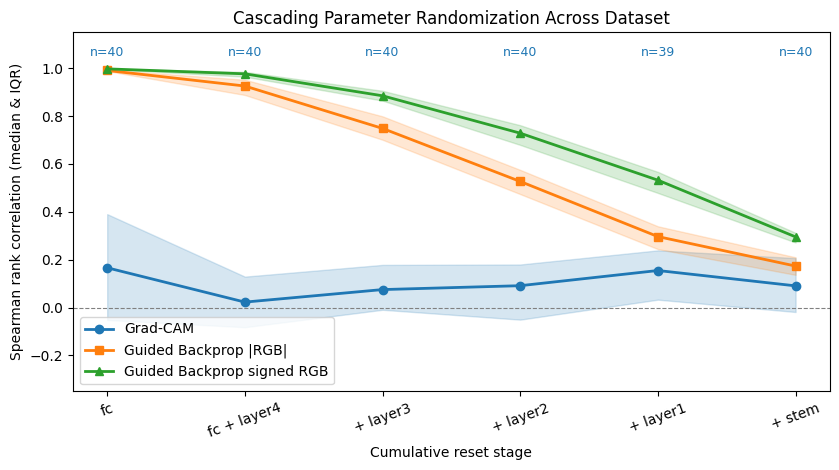

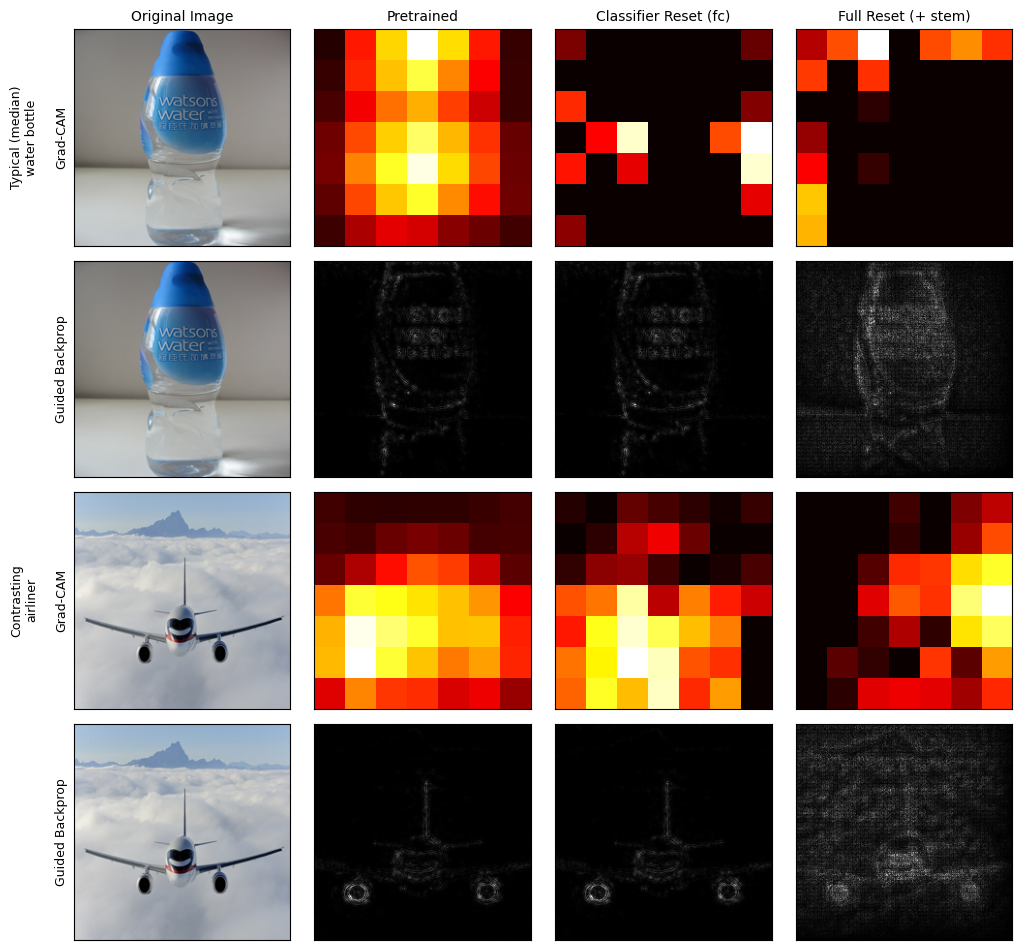

In [ ]:
# --- FIGURE 1: Similarity curves with middle-50% (IQR) bands & valid Grad-CAM counts ---
fig, ax = plt.subplots(figsize=(8.5, 4.8))

curve_specs = [
    ("gradcam", "Grad-CAM", "#1f77b4", "o"),
    ("guided_abs_rgb", "Guided Backprop |RGB|", "#ff7f0e", "s"),
    ("guided_signed_rgb", "Guided Backprop signed RGB", "#2ca02c", "^"),
]

x_pos = list(range(len(stage_order)))
for col, label, color, marker in curve_specs:
    agg = (
        per_image.groupby("stage")[col]
        .agg(
            median="median",
            q25=lambda s: s.quantile(0.25),
            q75=lambda s: s.quantile(0.75),
        )
        .reindex(stage_order)
    )
    ax.plot(x_pos, agg["median"], marker=marker, color=color, linewidth=2, label=label)
    ax.fill_between(x_pos, agg["q25"], agg["q75"], color=color, alpha=0.18)

valid_n = (
    per_image.groupby("stage")["gradcam"]
    .apply(lambda s: int(s.notna().sum()))
    .reindex(stage_order)
)
for i, n_val in enumerate(valid_n):
    ax.text(i, 1.04, f"n={n_val}", ha="center", va="bottom", fontsize=9, color="#1f77b4")

ax.set_xticks(x_pos)
ax.set_xticklabels(stage_order, rotation=20)
ax.set_ylim(-0.35, 1.15)
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlabel("Cumulative reset stage")
ax.set_ylabel("Spearman rank correlation (median & IQR)")
ax.set_title("Cascading Parameter Randomization Across Dataset")
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig("fig1_cascade_similarity.png", dpi=300, bbox_inches="tight")
plt.show()

# --- FIGURE 2: Qualitative grid (Pretrained vs. Classifier-reset vs. Full-reset) ---
fc_sorted = fc_df.assign(dist=(fc_df["gradcam"] - fc_df["gradcam"].median()).abs()).sort_values("dist")
typical_image = fc_sorted.iloc[0]["image"]
contrasting_image = fc_df.sort_values("gradcam", ascending=False).iloc[0]["image"]

selected = [(typical_image, "Typical (median)")]
if contrasting_image != typical_image:
    selected.append((contrasting_image, "Contrasting"))

def render_three_models(img_name, seed=42):
    with Image.open(BytesIO(uploaded[img_name])) as im:
        pil_rgb = ImageOps.exif_transpose(im).convert("RGB")
        batch = preprocess(pil_rgb).unsqueeze(0)
    with torch.no_grad():
        t_class = model(batch)[0].argmax().item()
    c_label = weights.meta["categories"][t_class]

    # Pretrained
    cam_0 = make_gradcam(model, batch, t_class)
    gbp_0 = make_guided_gradients(model, batch, t_class).abs()[0].amax(dim=0)

    # Classifier-reset ('fc' only, matching cascade seed 42)
    torch.manual_seed(seed)
    m_fc = deepcopy(model)
    m_fc.fc.reset_parameters()
    cam_fc = make_gradcam(m_fc, batch, t_class)
    gbp_fc = make_guided_gradients(m_fc, batch, t_class).abs()[0].amax(dim=0)

    # Full-reset (all layers reset, matching cascade '+ stem' seed 42)
    torch.manual_seed(seed + 1)
    m_full = resnet18(weights=None).eval()
    cam_full = make_gradcam(m_full, batch, t_class)
    gbp_full = make_guided_gradients(m_full, batch, t_class).abs()[0].amax(dim=0)

    return pil_rgb.resize((224, 224)), c_label, [cam_0, cam_fc, cam_full], [gbp_0, gbp_fc, gbp_full]

fig, axes = plt.subplots(2 * len(selected), 4, figsize=(10.5, 4.8 * len(selected)))
headers = ["Original Image", "Pretrained", "Classifier Reset (fc)", "Full Reset (+ stem)"]

for idx, (img_name, role_tag) in enumerate(selected):
    orig_pic, cls_name, cam_list, gbp_list = render_three_models(img_name, seed=SEEDS[0])
    r_cam, r_gbp = 2 * idx, 2 * idx + 1

    axes[r_cam, 0].imshow(orig_pic)
    axes[r_cam, 0].set_ylabel(f"{role_tag}\n{cls_name}\n\nGrad-CAM", fontsize=9)
    axes[r_gbp, 0].imshow(orig_pic)
    axes[r_gbp, 0].set_ylabel("Guided Backprop", fontsize=9)

    for j in range(3):
        axes[r_cam, j + 1].imshow(cam_list[j], cmap="hot", interpolation="nearest", vmin=0)
        axes[r_gbp, j + 1].imshow(gbp_list[j], cmap="gray", vmin=0)

    if idx == 0:
        for j, h in enumerate(headers):
            axes[r_cam, j].set_title(h, fontsize=10)

for row_ax in axes:
    for cell_ax in row_ax:
        cell_ax.set_xticks([])
        cell_ax.set_yticks([])

plt.tight_layout()
plt.savefig("fig2_qualitative_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Extra experiment: Independent reset (`fc`-only vs. `stem`-only)

Starting from the pretrained ResNet-18 for each condition, compare resetting **only `fc`** against resetting **only `stem` (`conv1` + `bn1`)**. This isolates whether corrupting only the earliest edge-detecting layers is sufficient to alter Guided Backpropagation when all upper layers remain pretrained.

In [ ]:
indep_rows = []

for image_name, image_bytes in uploaded.items():
    with Image.open(BytesIO(image_bytes)) as image:
        input_batch = preprocess(ImageOps.exif_transpose(image).convert("RGB")).unsqueeze(0)

    with torch.no_grad():
        target_class = model(input_batch)[0].argmax().item()
    class_name = weights.meta["categories"][target_class]

    original_cam = make_gradcam(model, input_batch, target_class)
    original_guided = make_guided_gradients(model, input_batch, target_class)
    original_magnitude = original_guided.abs()

    for seed in SEEDS:
        torch.manual_seed(seed)
        m_fc_only = deepcopy(model)
        m_fc_only.fc.reset_parameters()

        torch.manual_seed(seed + 1)
        fresh_model = resnet18(weights=None)
        m_stem_only = deepcopy(model)
        for name in ("conv1", "bn1"):
            getattr(m_stem_only, name).load_state_dict(
                getattr(fresh_model, name).state_dict()
            )

        for cond_label, test_m in [("only_fc", m_fc_only), ("only_stem", m_stem_only)]:
            cam = make_gradcam(test_m, input_batch, target_class)
            guided = make_guided_gradients(test_m, input_batch, target_class)
            indep_rows.append({
                "image": image_name,
                "target_class": target_class,
                "class_name": class_name,
                "seed": seed,
                "condition": cond_label,
                "gradcam": rank_similarity(original_cam, cam),
                "guided_abs_rgb": rank_similarity(original_magnitude, guided.abs()),
                "guided_signed_rgb": rank_similarity(original_guided, guided),
            })

indep_results = pd.DataFrame(indep_rows)
indep_results.to_csv("independent_reset_results.csv", index=False)
print(f"Saved {len(indep_results)} rows to independent_reset_results.csv.\n")

indep_per_img = indep_results.groupby(["image", "condition"], as_index=False)[metrics].mean()
indep_summary = []
for cond in ["only_fc", "only_stem"]:
    sub = indep_per_img[indep_per_img["condition"] == cond]
    row = {"condition": cond, "valid_images_gradcam": int(sub["gradcam"].notna().sum())}
    for m in metrics:
        q25, med, q75 = sub[m].quantile([0.25, 0.50, 0.75])
        row[f"{m}_median"] = round(med, 3)
        row[f"{m}_IQR"] = f"[{q25:.3f}, {q75:.3f}]"
    indep_summary.append(row)

display(pd.DataFrame(indep_summary))

Saved 240 rows to independent_reset_results.csv.



,condition,valid_images_gradcam,gradcam_median,gradcam_IQR,guided_abs_rgb_median,guided_abs_rgb_IQR,guided_signed_rgb_median,guided_signed_rgb_IQR
0,only_fc,40,0.166,"[-0.052, 0.390]",0.991,"[0.988, 0.994]",0.997,"[0.996, 0.998]"
1,only_stem,36,0.190,"[-0.076, 0.358]",0.171,"[0.133, 0.215]",0.198,"[0.169, 0.218]"
